# NY Housing Price Prediction
**Predicting New York City listing prices with multiple linear regression**

## Overview
**Objective.** Build and evaluate a linear regression model that predicts the listing price of a New York City property from its size, layout, location and type.

**Dataset.** `NYHousing.csv` contains 4,801 property listings with 17 columns (price, beds, baths, square footage, property type, address fields and coordinates).

**Approach.**
1. Inspect the data and remove duplicates and placeholder (mean-imputed) values.
2. Explore distributions and correlations.
3. Remove implausible records and log-transform the target.
4. Cap outliers using training-set thresholds, check multicollinearity (VIF) and fit a baseline linear regression.
5. Add borough (cleaned from `SUBLOCALITY`) and property type (cleaned from `TYPE`) and compare against the baseline.
6. Compare the linear model with Random Forest and Gradient Boosting.

## Key results
| Model | Features | R² (log price) | MAE (USD) |
|---|---|---|---|
| Baseline linear regression | BEDS, BATH, PROPERTYSQFT, LATITUDE, LONGITUDE | 0.521 | 634,464 |
| Expanded linear regression | Baseline + borough + property type | **0.748** | **458,616** |
| Random Forest | Same as expanded | 0.843 | 340,404 |
| Gradient Boosting | Same as expanded | 0.845 | 345,008 |

Adding borough and property type raises R² by about 23 percentage points and cuts the average dollar error by about 28%. The tree-based models improve further, but linear regression is kept as the main model because its coefficients are interpretable.

## How to run
1. Download `NYHousing.csv` and save it on your machine.
2. In Step 1, set the path inside `pd.read_csv(...)` to the file's location.
3. Run all cells from top to bottom (Kernel → Restart & Run All).

## Requirements
`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `statsmodels`

## Setup
Import the libraries used throughout the notebook.

In [1]:
# Core libraries: data handling, plotting, modelling and statistical diagnostics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings("ignore")

## Step 1 — Load and Inspect the Data
Each row is one property listing. This step loads the file, removes duplicates and checks the quality of the key columns (`PRICE`, `BEDS`, `BATH`, `PROPERTYSQFT`).

In [2]:
# Load the dataset (update this path to wherever NYHousing.csv is saved on your machine)
df = pd.read_csv(r"data\NYHousing.csv")
print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

Dataset Shape: (4801, 17)

Columns: ['BROKERTITLE', 'TYPE', 'PRICE', 'BEDS', 'BATH', 'PROPERTYSQFT', 'ADDRESS', 'STATE', 'MAIN_ADDRESS', 'ADMINISTRATIVE_AREA_LEVEL_2', 'LOCALITY', 'SUBLOCALITY', 'STREET_NAME', 'LONG_NAME', 'FORMATTED_ADDRESS', 'LATITUDE', 'LONGITUDE']


### 1.1 First look

In [3]:
# Preview the first 5 rows of the dataset
df.head()

,BROKERTITLE,TYPE,PRICE,BEDS,BATH,PROPERTYSQFT,ADDRESS,STATE,MAIN_ADDRESS,ADMINISTRATIVE_AREA_LEVEL_2,LOCALITY,SUBLOCALITY,STREET_NAME,LONG_NAME,FORMATTED_ADDRESS,LATITUDE,LONGITUDE
0,Brokered by Douglas Elliman -111 Fifth Ave,Condo for sale,315000,2,2.000000,1400.0,2 E 55th St Unit 803,"New York, NY 10022","2 E 55th St Unit 803New York, NY 10022",New York County,New York,Manhattan,East 55th Street,Regis Residence,"Regis Residence, 2 E 55th St #803, New York, N...",40.761255,-73.974483
1,Brokered by Serhant,Condo for sale,195000000,7,10.000000,17545.0,Central Park Tower Penthouse-217 W 57th New Yo...,"New York, NY 10019",Central Park Tower Penthouse-217 W 57th New Yo...,United States,New York,New York County,New York,West 57th Street,"217 W 57th St, New York, NY 10019, USA",40.766393,-73.980991
2,Brokered by Sowae Corp,House for sale,260000,4,2.000000,2015.0,620 Sinclair Ave,"Staten Island, NY 10312","620 Sinclair AveStaten Island, NY 10312",United States,New York,Richmond County,Staten Island,Sinclair Avenue,"620 Sinclair Ave, Staten Island, NY 10312, USA",40.541805,-74.196109
3,Brokered by COMPASS,Condo for sale,69000,3,1.000000,445.0,2 E 55th St Unit 908W33,"Manhattan, NY 10022","2 E 55th St Unit 908W33Manhattan, NY 10022",United States,New York,New York County,New York,East 55th Street,"2 E 55th St, New York, NY 10022, USA",40.761398,-73.974613
4,Brokered by Sotheby's International Realty - E...,Townhouse for sale,55000000,7,2.373861,14175.0,5 E 64th St,"New York, NY 10065","5 E 64th StNew York, NY 10065",United States,New York,New York County,New York,East 64th Street,"5 E 64th St, New York, NY 10065, USA",40.767224,-73.969856


### 1.2 Remove duplicate listings
214 rows are exact duplicates. Removing them leaves 4,587 listings.

In [4]:
# Count fully duplicated rows
df.duplicated().sum()

np.int64(214)

In [5]:
# Remove exact duplicate rows
df= df.drop_duplicates()
df.shape

(4587, 17)

### 1.3 Detect and remove mean-imputed values
Many `PROPERTYSQFT` and `BATH` entries share exactly the same value (2184.21 sq ft and 2.37 baths), which suggests the source data filled in missing values with the column mean. These placeholders do not describe real properties and would weaken the size-price relationship, so they are removed.

- 1,539 listings have an imputed `PROPERTYSQFT`
- 288 listings have an imputed `BATH`
- 1,709 listings are affected in total, leaving **2,878** listings

In [6]:
# Detect mean-imputed placeholders (missing PROPERTYSQFT / BATH appear to be filled with the column mean)
imp_sqft = np.isclose(df["PROPERTYSQFT"], 2184.207862, atol=1e-3)
imp_bath = np.isclose(df["BATH"], 2.373861, atol=1e-3)
print(imp_sqft.sum(), imp_bath.sum(), (imp_sqft | imp_bath).sum())

1539 288 1709


In [7]:
# Drop rows with imputed values so the model trains on real measurements only
df = df[~(imp_sqft | imp_bath)].reset_index(drop=True)
df.shape

(2878, 17)

### 1.4 Data types, summary statistics and missing values

In [8]:
# Data types and non-null counts
df[["PRICE", "BEDS", "BATH", "PROPERTYSQFT"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2878 entries, 0 to 2877
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PRICE         2878 non-null   int64  
 1   BEDS          2878 non-null   int64  
 2   BATH          2878 non-null   float64
 3   PROPERTYSQFT  2878 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 90.1 KB


In [9]:
# Summary statistics (note the extreme maximum values)
df[["PRICE", "BEDS", "BATH", "PROPERTYSQFT"]].describe().round(2)

,PRICE,BEDS,BATH,PROPERTYSQFT
count,2.878000e+03,2878.00,2878.00,2878.00
mean,2.641608e+06,3.44,2.51,2012.82
std,4.032140e+07,2.89,2.25,2051.51
min,6.000000e+04,1.00,0.00,230.00
25%,5.290000e+05,2.00,1.00,939.25
50%,8.499985e+05,3.00,2.00,1440.00
75%,1.585500e+06,4.00,3.00,2340.00
max,2.147484e+09,50.00,50.00,33000.00


In [10]:
# Confirm there are no missing values in the key columns
print("Missing Values:")
print(df[["PRICE", "BEDS", "BATH", "PROPERTYSQFT"]].isnull().sum())

Missing Values:
PRICE           0
BEDS            0
BATH            0
PROPERTYSQFT    0
dtype: int64


**Findings**
- All four key columns have the correct numeric types and no missing values remain.
- Extreme values are present: the maximum price is about \$2.15 billion (equal to the 32-bit integer limit, so almost certainly a data error), and the maximum `BEDS`, `BATH` and `PROPERTYSQFT` are 50, 50 and 33,000.
- The mean price (\$2.64M) is far above the median (\$850K), which signals a heavily right-skewed distribution driven by a few extreme listings.

## Step 2 — Exploratory Data Analysis
Histograms and boxplots show the shape of each variable, and the heatmap shows pairwise correlations.

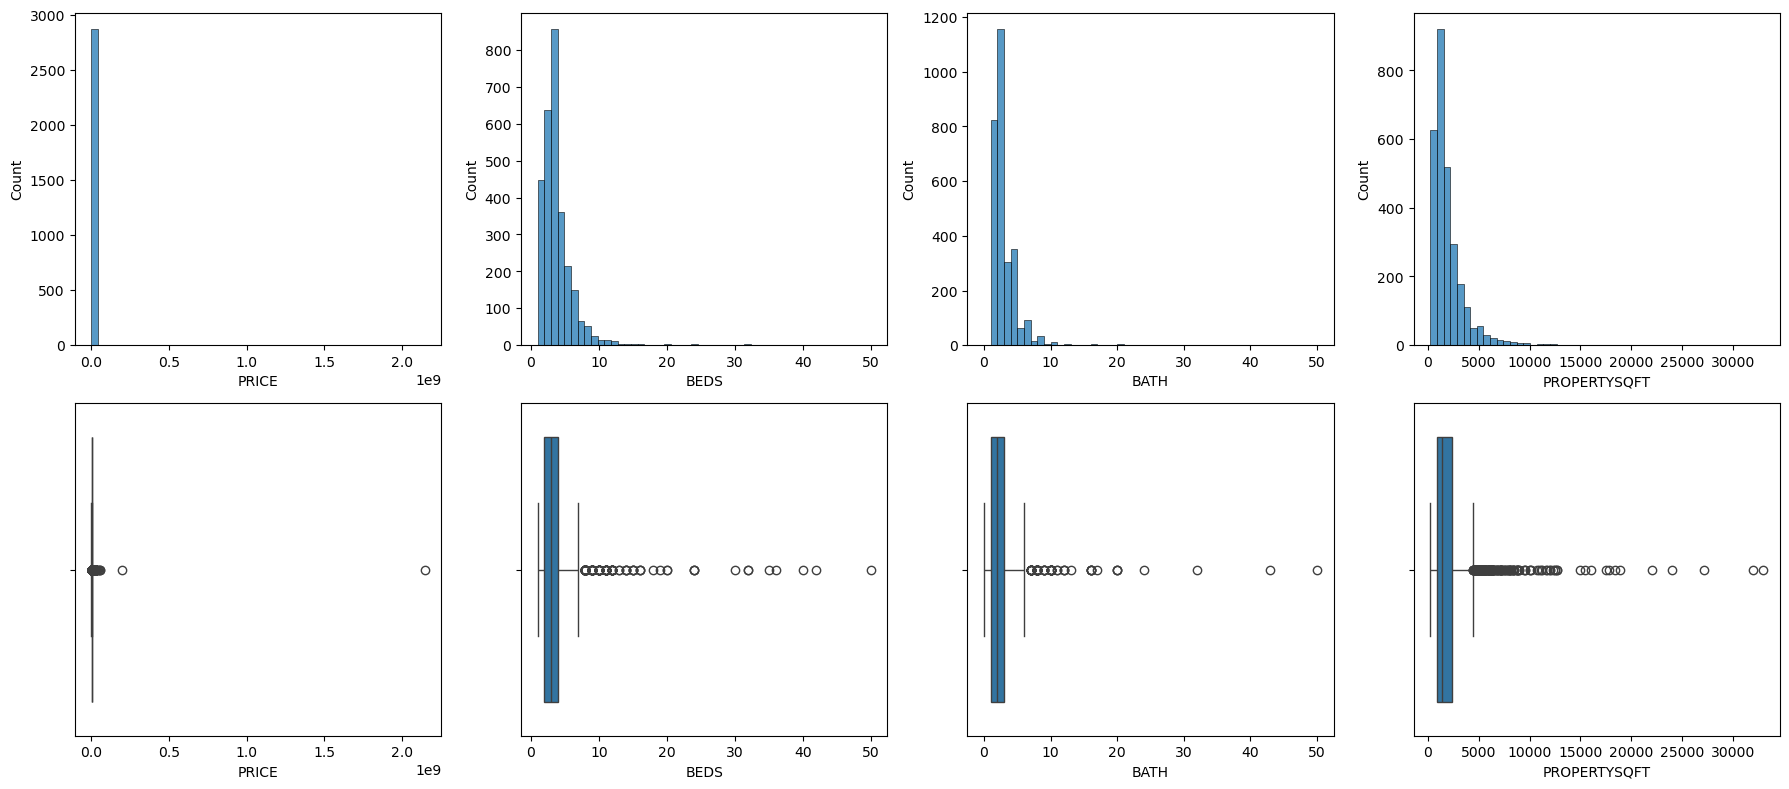

<Axes: >

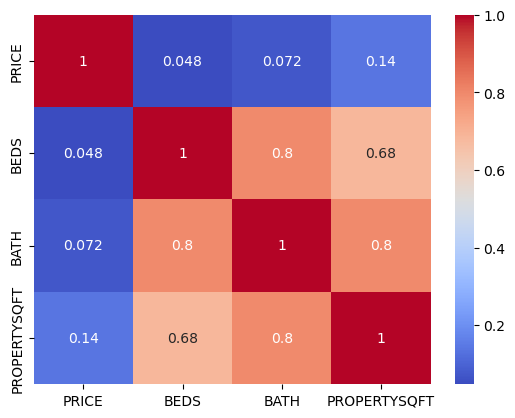

In [11]:
# Histograms and boxplots of the key variables, followed by a correlation heatmap
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for i, c in enumerate(["PRICE", "BEDS", "BATH", "PROPERTYSQFT"]):
    sns.histplot(df[c], bins=50, ax=ax[0, i])
    sns.boxplot(x=df[c], ax=ax[1, i])
plt.tight_layout(); plt.show()

sns.heatmap(df[["PRICE","BEDS","BATH","PROPERTYSQFT"]].corr(), annot=True, cmap="coolwarm")

**Interpretation**
- All four variables are right-skewed with long upper tails, as the boxplots show.
- `BEDS`, `BATH` and `PROPERTYSQFT` are strongly correlated with each other (BEDS–BATH 0.80, BATH–PROPERTYSQFT 0.80, BEDS–PROPERTYSQFT 0.68), so multicollinearity needs to be tested formally (Step 4.2).
- `PRICE` has weak linear correlations with the three features (0.05, 0.07 and 0.14). This is expected because extreme values distort the correlation coefficient, which motivates the outlier handling and log transformation in Step 3.

## Step 3 — Data Preparation
Remove implausible records and transform the target. Outlier capping is applied after the train/test split in Step 4 so that no information from the test set is used.

### 3.1 Remove implausible records
Listings priced at \$10M or more, with more than 20 bedrooms, or with 65,000 sq ft or more are either data errors or ultra-luxury properties that do not represent the typical market and would dominate a linear model. This removes 96 listings. The count printed below (2,782) is the number of rows that remain.

In [12]:
# Remove implausible records: price of $10M or more, more than 20 beds, 65,000+ sq ft
df = df[(df["PRICE"] < 1e7) & (df["BEDS"] <= 20) & (df["PROPERTYSQFT"] < 65000)].reset_index(drop=True)
print(f"Rows before: {len(df)}")

Rows before: 2782


### 3.2 Price distribution after filtering

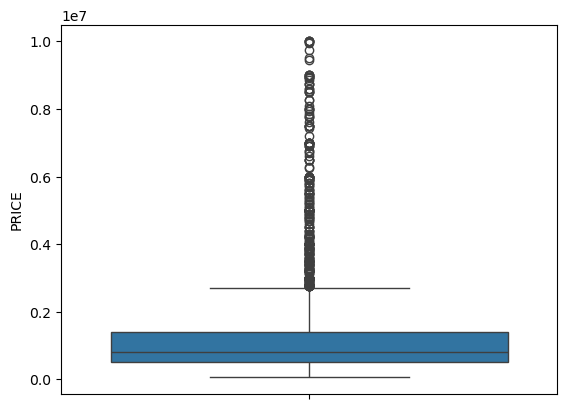

In [13]:
# Price distribution after removing implausible records
sns.boxplot(y=df['PRICE'])
plt.show()

Price is still right-skewed after filtering: the mean (\$1.31M) is well above the median (\$0.80M).

### 3.3 Check the location coordinates
`LATITUDE` and `LONGITUDE` are used directly as numeric location features, so their distributions are checked first.

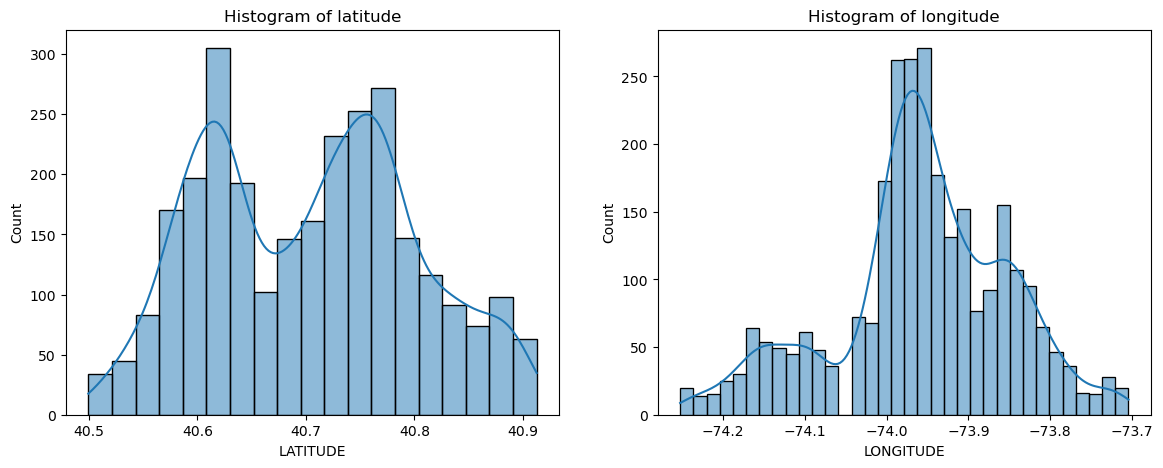

In [14]:
# Check the spread of the location coordinates
fig, ax= plt.subplots(1,2,figsize=(14,5))
sns.histplot(df['LATITUDE'], kde=True, ax= ax[0])
ax[0].set_title('Histogram of latitude')
sns.histplot(df['LONGITUDE'], kde=True, ax= ax[1])
ax[1].set_title('Histogram of longitude')
plt.show()

### 3.4 Log-transform the target
Taking the natural log of price reduces the right skew and makes the relationship with the predictors closer to linear. The model therefore predicts `log(PRICE)`, and predictions are converted back to dollars with `exp()` when reporting MAE.

In [15]:
# Log-transform the target to reduce right skew
df['log_pr']= np.log(df['PRICE'])

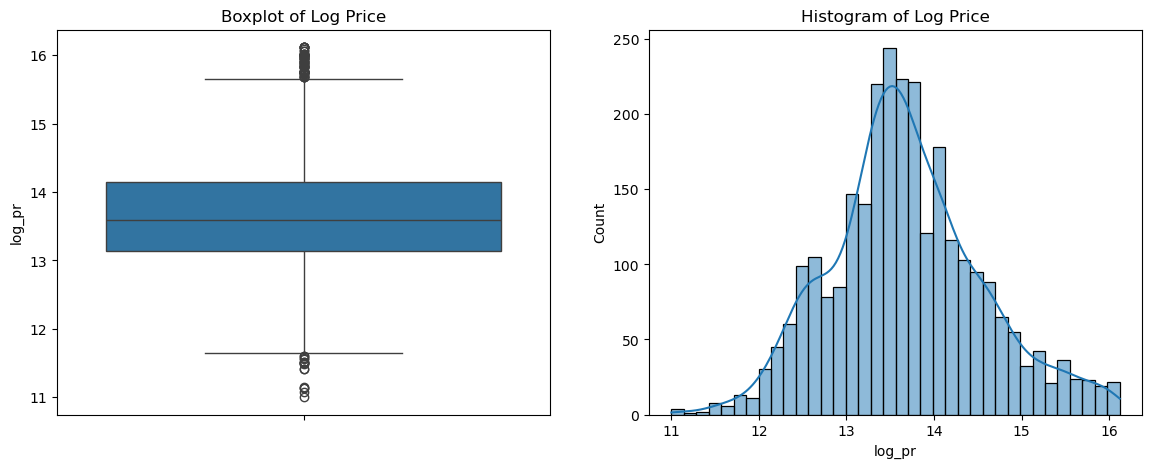

In [16]:
# Compare the shape of log price (boxplot and histogram)
fig, ax= plt.subplots(1,2,figsize=(14,5))
sns.boxplot(df['log_pr'], ax= ax[0])
ax[0].set_title('Boxplot of Log Price')
sns.histplot(df['log_pr'], kde=True, ax= ax[1])
ax[1].set_title('Histogram of Log Price')
plt.show()

### 3.5 Working dataset summary

In [17]:
# Working copy and summary statistics (before capping; capping is applied after the split in Step 4)
df_clean= df.copy()
df_clean[["log_pr", "BEDS", "BATH", "PROPERTYSQFT"]].describe().round(2)

,log_pr,BEDS,BATH,PROPERTYSQFT
count,2782.00,2782.00,2782.00,2782.00
mean,13.68,3.25,2.33,1808.86
std,0.87,2.13,1.60,1459.87
min,11.00,1.00,0.00,230.00
25%,13.14,2.00,1.00,916.75
50%,13.59,3.00,2.00,1400.00
75%,14.15,4.00,3.00,2228.25
max,16.12,20.00,32.00,32000.00


**Interpretation**
- Log price is close to symmetric (mean 13.68 vs median 13.59, standard deviation 0.87), so the log transformation worked.
- The features still contain extreme maxima (`BEDS` up to 20, `BATH` up to 32, `PROPERTYSQFT` up to 32,000). These are capped in Step 4 using IQR fences calculated on the training set only.

## Step 4 — Baseline Linear Regression
The baseline uses size, layout and location coordinates: `BEDS`, `BATH`, `PROPERTYSQFT`, `LATITUDE` and `LONGITUDE`.

### 4.1 Features, train/test split and outlier capping
- **Target:** `log(PRICE)`.
- **Split:** 80% training (2,225 rows) and 20% testing (557 rows), `random_state=42`.
- **Capping (winsorization):** `BEDS`, `BATH` and `PROPERTYSQFT` are clipped to the IQR fences (Q1 − 1.5·IQR, Q3 + 1.5·IQR) calculated on the training set and applied to both sets. The target and the coordinates are not capped.

In [18]:
# Define features (X) and the log-price target (y)
X = df_clean[["BEDS", "BATH", "PROPERTYSQFT", 'LONGITUDE', 'LATITUDE']]
y = df_clean["log_pr"]

# Train-Test Split — 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Cap outliers in BEDS, BATH and PROPERTYSQFT using IQR fences learned from the training set only (avoids data leakage)
for c in ["BEDS", "BATH", "PROPERTYSQFT"]:
    q1, q3 = X_train[c].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    X_train[c] = X_train[c].clip(lo, hi)
    X_test[c]  = X_test[c].clip(lo, hi)

print("x_size:", X_train.shape)
print("y_size:", y_train.shape)
print(f"\nTraining set: {X_train.shape[0]} rows")
print(f"Test set:     {X_test.shape[0]} rows")

x_size: (2225, 5)
y_size: (2225,)

Training set: 2225 rows
Test set:     557 rows


### 4.2 Multicollinearity check (VIF)

In [19]:
# Variance Inflation Factor (VIF) on the training features; VIF above 5 would signal problematic multicollinearity
Xv = add_constant(X_train)
vif = pd.DataFrame({
    "feature": Xv.columns,
    "VIF": [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]
})
print(vif[vif.feature != "const"])

        feature       VIF
1          BEDS  2.605634
2          BATH  3.524009
3  PROPERTYSQFT  3.830290
4     LONGITUDE  1.648678
5      LATITUDE  1.627134


**Interpretation.** The heatmap showed strong pairwise correlations between `BEDS`, `BATH` and `PROPERTYSQFT` (about 0.7 to 0.8). The VIF values are all below 5 (highest: `PROPERTYSQFT` at 3.83, then `BATH` at 3.52), so multicollinearity is not severe and all features are kept. The coefficients are still best read as the effect of each feature holding the others constant.

### 4.3 Fit the model and read the coefficients
The target is log price, so each coefficient is the change in log price per unit of the feature. For small values this is approximately a percentage change (exact change = exp(coefficient) − 1).

In [20]:
# Fit the baseline linear regression (the target is log price, so coefficients are in log-points, not USD)
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept (B0):   {model.intercept_:,.2f}")
print("\nCoefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(f"  {feature:<15}   {coef:,.2f}")

Intercept (B0):   -109.30

Coefficients:
  BEDS              -0.10
  BATH              0.18
  PROPERTYSQFT      0.00
  LONGITUDE         -1.06
  LATITUDE          1.06


**Interpretation** (holding the other features constant)
- **`BATH` (0.18):** each extra bathroom is associated with about 20% higher price.
- **`PROPERTYSQFT` (about 0.0005):** each extra 100 sq ft is associated with about 5% higher price (it prints as 0.00 only because of rounding).
- **`BEDS` (−0.10):** each extra bedroom is associated with about 10% *lower* price. This is counter-intuitive but not necessarily an error: bedrooms are strongly correlated with bathrooms and size, so once those are held fixed, more bedrooms means smaller rooms.
- **`LATITUDE` (+1.06) and `LONGITUDE` (−1.06):** these are large and nearly equal and opposite because they act together as a location signal. They should be read jointly rather than individually.

### 4.4 Evaluate on the test set
Two metrics are used: **MAE** (average dollar error) and **R²** (share of variation in log price explained by the model).

In [21]:
# Predict on test set
y_pred = model.predict(X_test)

# Test 1 — MAE in dollars (log predictions are converted back with exp)
mae_usd = mean_absolute_error(np.exp(y_test), np.exp(y_pred))
print(f"Test 1 - MAE:      USD {mae_usd:,.2f}")

# Test 2 — R² on the log-price scale
r2 = r2_score(y_test, y_pred)
print(f"Test 2 - R2 Score: {r2:.4f} ({r2*100:.2f}%)")

print(f"\nMean cleaned housing price: USD {df_clean['PRICE'].mean():,.2f}")

Test 1 - MAE:      USD 634,464.42
Test 2 - R2 Score: 0.5209 (52.09%)

Mean cleaned housing price: USD 1,313,974.11


**Interpretation**
- **MAE = \$634,464.** Predictions are off by about \$634K on average, which is about 48% of the mean price (\$1.31M) and about 79% of the median (\$0.80M). That is a large error.
- **R² = 0.5209.** The baseline explains about 52% of the variation in log price, so almost half of what drives price is still unexplained.
- The baseline has no information on property type and describes location only through raw coordinates, which motivates Step 5.

## Step 5 — Adding Borough and Property Type
Two categorical variables are added to the baseline:
1. **Borough**, cleaned from the messy `SUBLOCALITY` column.
2. **Property type**, cleaned from the `TYPE` column.

### 5.1 Inspect `SUBLOCALITY`

In [22]:
# Inspect the raw SUBLOCALITY labels (a mix of borough, county and neighbourhood names)
print(df_clean["SUBLOCALITY"].value_counts())

SUBLOCALITY
New York            511
Kings County        441
Richmond County     400
Brooklyn            354
Queens              268
Queens County       259
Bronx County        218
The Bronx           139
New York County     113
Staten Island        54
Manhattan            12
Coney Island          3
Riverdale             2
Flushing              2
East Bronx            1
Brooklyn Heights      1
Rego Park             1
Fort Hamilton         1
Dumbo                 1
Snyder Avenue         1
Name: count, dtype: int64


`SUBLOCALITY` has 20 different labels for what should be five boroughs. It mixes borough names (Brooklyn), county names (Kings County) and neighbourhood names (Dumbo), so it cannot be used as-is.

### 5.2 Standardise to five boroughs
Labels are mapped to boroughs using the county equivalents (New York County = Manhattan, Kings County = Brooklyn, Richmond County = Staten Island, plus Queens and Bronx). The label "New York" (511 rows) is treated as Manhattan. Thirteen neighbourhood labels could not be mapped at first, so they are added manually. A ZIP-code fallback is included as a safeguard; after the manual mapping no listing remains unmapped, so it changes nothing here.

In [23]:
# Map SUBLOCALITY labels to the five boroughs
borough_map = {
    "Manhattan": "Manhattan", "New York County": "Manhattan", "New York": "Manhattan",
    "Brooklyn": "Brooklyn", "Kings County": "Brooklyn",
    "Queens": "Queens", "Queens County": "Queens",
    "The Bronx": "Bronx", "Bronx": "Bronx", "Bronx County": "Bronx",
    "Staten Island": "Staten Island", "Richmond County": "Staten Island",
}
df_clean["BOROUGH"] = df_clean["SUBLOCALITY"].map(borough_map)
print(df_clean["BOROUGH"].isna().sum(), "unmapped")
print(df_clean[df_clean["BOROUGH"].isna()]["SUBLOCALITY"].value_counts())

13 unmapped
SUBLOCALITY
Coney Island        3
Riverdale           2
Flushing            2
East Bronx          1
Brooklyn Heights    1
Rego Park           1
Fort Hamilton       1
Dumbo               1
Snyder Avenue       1
Name: count, dtype: int64


In [24]:
# Add the remaining neighbourhood names to the mapping and re-apply it
borough_map.update({
    "Riverdale": "Bronx", "East Bronx": "Bronx",
    "Flushing": "Queens", "Jackson Heights": "Queens", "Rego Park": "Queens",
    "Coney Island": "Brooklyn", "Brooklyn Heights": "Brooklyn",
    "Fort Hamilton": "Brooklyn", "Dumbo": "Brooklyn", "Snyder Avenue": "Brooklyn",
})
df_clean["BOROUGH"] = df_clean["SUBLOCALITY"].map(borough_map)
print(df_clean["BOROUGH"].isna().sum(), "unmapped")   # expect 0 after the update
print(df_clean["BOROUGH"].value_counts())

0 unmapped
BOROUGH
Brooklyn         802
Manhattan        636
Queens           530
Staten Island    454
Bronx            360
Name: count, dtype: int64


In [25]:
# Fallback: fill any unmapped boroughs using the ZIP-code prefix
z = df_clean["STATE"].str.extract(r"(\d{5})")[0].str[:3].astype(int)
zip_map = {100:"Manhattan",101:"Manhattan",102:"Manhattan",103:"Staten Island",
           104:"Bronx",112:"Brooklyn",110:"Queens",111:"Queens",113:"Queens",114:"Queens",116:"Queens"}
df_clean["BOROUGH"] = df_clean["BOROUGH"].fillna(z.map(zip_map))

After mapping, every listing has a borough: Brooklyn (802), Manhattan (636), Queens (530), Staten Island (454) and Bronx (360).

### 5.3 Clean the property type
`TYPE` mixes real property types with listing statuses. The five main property types are kept (Condo, Co-op, House, Multi-family home, Townhouse) and everything else is grouped into **Other** (232 listings): mostly the statuses "Pending" (132) and "Contingent" (76), plus a few "For sale", "Foreclosure", "Coming Soon" and "Land" listings. The "Other" category does not describe what kind of property it is, which should be kept in mind when reading its coefficient.

In [26]:
# Clean property type: keep the five real property types and group listing statuses (Pending, Contingent, ...) as 'Other'
valid = ["Condo", "Co-op", "House", "Multi-family home", "Townhouse"]
df_clean["PROP_TYPE"] = (df_clean["TYPE"].str.replace(" for sale", "", regex=False)
                         .where(lambda s: s.isin(valid), "Other"))
print(df_clean["PROP_TYPE"].value_counts())

PROP_TYPE
Condo                689
Co-op                666
House                637
Multi-family home    406
Other                232
Townhouse            152
Name: count, dtype: int64


In [27]:
# Sanity-check the engineered features
df_clean[["PROP_TYPE", 'log_pr',"BEDS", "BATH", "PROPERTYSQFT", "SUBLOCALITY","BOROUGH"]].head()

,PROP_TYPE,log_pr,BEDS,BATH,PROPERTYSQFT,SUBLOCALITY,BOROUGH
0,Condo,12.660328,2,2.0,1400.0,Manhattan,Manhattan
1,House,12.468437,4,2.0,2015.0,Richmond County,Staten Island
2,Condo,11.141862,3,1.0,445.0,New York County,Manhattan
3,House,13.444447,5,2.0,4004.0,Kings County,Brooklyn
4,Co-op,12.487485,1,1.0,750.0,East Bronx,Bronx


### 5.4 One-hot encode the categorical variables
Property type and borough are converted to 0/1 indicator columns, dropping the first category of each as the baseline (Co-op for property type, Bronx for borough). The feature matrix then combines the five numeric features with these indicators.

In [28]:
# One-hot encode categorical features (drop_first=True avoids the dummy-variable trap) and build the feature matrix
df_clean = pd.get_dummies(df_clean, columns=["PROP_TYPE", "BOROUGH"], drop_first=True)
type_cols = [c for c in df_clean.columns if c.startswith("PROP_TYPE_")]
borough_cols = [c for c in df_clean.columns if c.startswith("BOROUGH_")]   # borough dummy columns

num_feats = ["BEDS", "BATH", "PROPERTYSQFT", 'LATITUDE', 'LONGITUDE']
X = df_clean[num_feats + borough_cols + type_cols].astype(float)
y = df_clean["log_pr"]

### 5.5 Median price by borough
A quick check that borough carries real information about price.

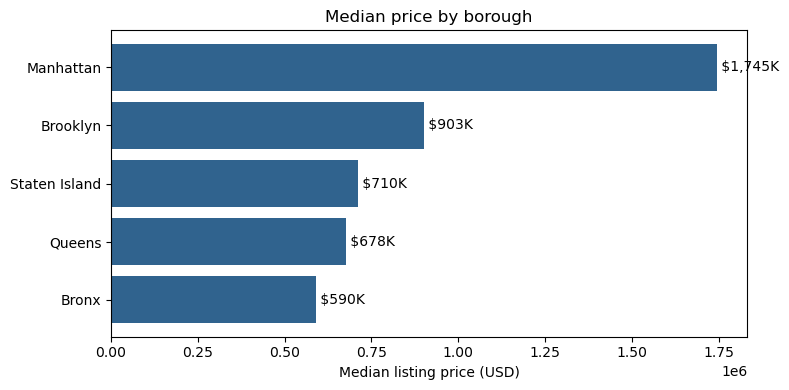

In [29]:
# Median listing price by borough (borough rebuilt from the dummy columns)
dummies = df_clean[borough_cols].astype(int)
borough = dummies.idxmax(axis=1).str.replace("BOROUGH_", "", regex=False)
borough[dummies.sum(axis=1) == 0] = "Bronx"            # the dropped (baseline) category
med = df_clean.groupby(borough)["PRICE"].median().sort_values()

plt.figure(figsize=(8, 4))
plt.barh(med.index, med.values, color="#30638e")
for i, v in enumerate(med.values):
    plt.text(v, i, f" ${v/1e3:,.0f}K", va="center")
plt.xlabel("Median listing price (USD)")
plt.title("Median price by borough")
plt.tight_layout(); plt.show()

Prices differ sharply by borough: the median in Manhattan (about \$1.74M) is roughly three times the median in the Bronx (about \$590K), with Brooklyn (about \$903K), Staten Island (about \$710K) and Queens (about \$678K) in between. This supports adding borough as a feature.

### 5.6 Re-split, cap and refit
The same split (`random_state=42`) and the same training-set capping are used as in the baseline, so results are directly comparable.

In [30]:
# Re-split with the same random_state, cap numeric features using training-set fences, and refit
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for c in ["BEDS", "BATH", "PROPERTYSQFT"]:
    q1, q3 = X_train[c].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    X_train[c] = X_train[c].clip(lo, hi)
    X_test[c]  = X_test[c].clip(lo, hi)

model = LinearRegression().fit(X_train, y_train)

In [31]:
# Print the intercept and coefficients of the expanded model (log-price scale)
print(f"Intercept (B0):   {model.intercept_:,.2f}")
print("\nCoefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(f"  {feature:<15}   {coef:,.2f}")

Intercept (B0):   -218.13

Coefficients:
  BEDS              -0.02
  BATH              0.10
  PROPERTYSQFT      0.00
  LATITUDE          1.63
  LONGITUDE         -2.21
  BOROUGH_Brooklyn   0.65
  BOROUGH_Manhattan   1.00
  BOROUGH_Queens    0.67
  BOROUGH_Staten Island   -0.03
  PROP_TYPE_Condo   0.58
  PROP_TYPE_House   0.54
  PROP_TYPE_Multi-family home   0.32
  PROP_TYPE_Other   0.32
  PROP_TYPE_Townhouse   0.43


**Interpretation of the expanded model's coefficients** (target is log price; exact percentage change = exp(coefficient) − 1; all else held constant)
- **Property type (vs Co-op):** Condo +0.58 (about +79%), House +0.54 (+71%), Townhouse +0.43 (+53%), Multi-family +0.32 (+37%), Other +0.32 (+37%).
- **Borough (vs Bronx):** Manhattan +1.00 (about +172%), Queens +0.67 (+96%), Brooklyn +0.65 (+92%), Staten Island −0.03 (about −3%, essentially the same as the Bronx once the other features are controlled for). Because coordinates are also in the model, borough effects are partial effects.
- **Size and layout:** `BATH` +0.10 (about +11% per bathroom), `PROPERTYSQFT` about +0.0005 (about +5% per 100 sq ft) and `BEDS` −0.02 (about −2%, small and negative for the reason given in Step 4.3). These effects are smaller than in the baseline because borough and property type now absorb part of what size and layout were picking up.
- **`LATITUDE` (+1.63) and `LONGITUDE` (−2.21):** these act together as a location signal and are not meaningful individually.

### 5.7 Evaluate the expanded model

In [32]:
# Evaluate the expanded model on the test set
pred = model.predict(X_test)
r2= r2_score(y_test, pred)
mae_usd = mean_absolute_error(np.exp(y_test), np.exp(pred))
print(f"Test 1 - MAE:      USD {mae_usd:,.2f}")
print(f"Test 2 - R2 Score: {r2:.4f} ({r2*100:.2f}%)")

Test 1 - MAE:      USD 458,616.48
Test 2 - R2 Score: 0.7483 (74.83%)


**Interpretation**
- **R² = 0.7483** (up from 0.5209): the model now explains about 75% of the variation in log price.
- **MAE = \$458,616** (down from \$634,464): the average dollar error is about 35% of the mean price.
- Property type and borough carry a lot of information that size, layout and raw coordinates alone do not capture. Both metrics are calculated on the same 557 test listings as the baseline.

### 5.8 Predicted vs actual price

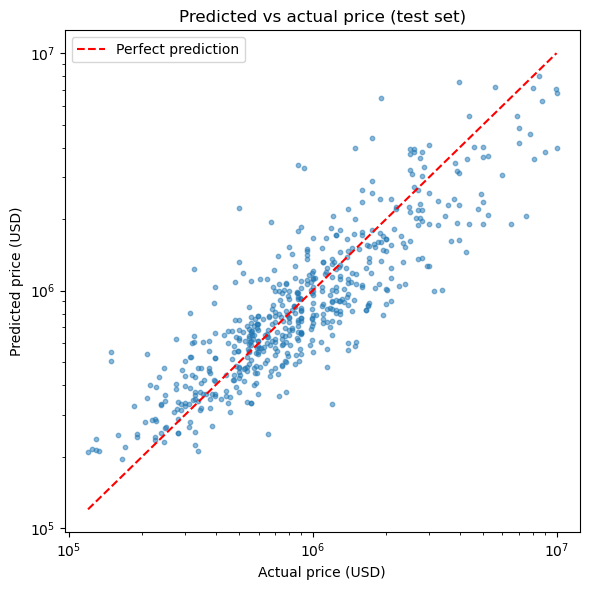

In [33]:
# Predicted vs actual price on the test set (dollars, log axes)
plt.figure(figsize=(6, 6))
plt.scatter(np.exp(y_test), np.exp(pred), s=10, alpha=0.5)
lims = [np.exp(y_test).min(), np.exp(y_test).max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual price (USD)"); plt.ylabel("Predicted price (USD)")
plt.title("Predicted vs actual price (test set)")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretation.** Predictions follow the diagonal closely across the whole price range (the correlation between actual and predicted log price is about 0.87). The model tends to under-predict the most expensive listings (above roughly \$3M) and over-predict some of the cheapest, and the spread widens at higher prices. This "pull towards the middle" is typical of linear models and suggests that interactions and non-linear effects are being missed, which Step 6 explores.

## Step 6 — Comparison with Tree-Based Models
Random Forest and Gradient Boosting are fitted on the same features and the same train/test split to see how much a non-linear model improves on linear regression. The models use default or lightly set parameters and are not tuned.

            Model  R² (log price)  MAE (USD)
Linear Regression          0.7483     458616
    Random Forest          0.8427     340404
Gradient Boosting          0.8454     345008


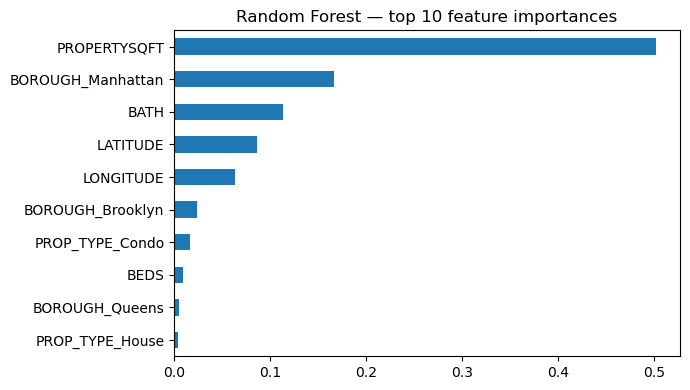

In [34]:
# Compare linear regression with tree-based models on the same train/test split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"Model": name,
                 "R² (log price)": round(r2_score(y_test, p), 4),
                 "MAE (USD)": round(mean_absolute_error(np.exp(y_test), np.exp(p)))})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

# Random forest feature importances (top 10)
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", figsize=(7, 4), title="Random Forest — top 10 feature importances")
plt.tight_layout(); plt.show()

**Interpretation**

| Model | R² (log price) | MAE (USD) |
|---|---|---|
| Linear Regression | 0.7483 | 458,616 |
| Random Forest | 0.8427 | 340,404 |
| Gradient Boosting | 0.8454 | 345,008 |

- Both tree-based models raise R² by about 0.10 and cut the average dollar error by about \$114K to \$118K (roughly 25%). This confirms that non-linear effects and interactions, such as the value of extra square footage differing by borough, matter for this data.
- Random Forest and Gradient Boosting perform almost identically (Gradient Boosting has the slightly higher R², Random Forest the slightly lower MAE), so neither is clearly better on this split.
- In the Random Forest, `PROPERTYSQFT` is by far the most important feature (about 0.50), followed by `BOROUGH_Manhattan` (about 0.17), `BATH` (about 0.11), `LATITUDE` (about 0.09) and `LONGITUDE` (about 0.06). Importances show how much the model relies on a feature, not the direction of its effect, and they tend to favour continuous features.
- The trade-off is interpretability: linear regression gives coefficients that can be explained in plain terms, which is why it remains the main model in this project.

## Step 7 — Results, Conclusion and Next Steps

### Model comparison
| | Baseline (linear) | Expanded (linear) | Random Forest | Gradient Boosting |
|---|---|---|---|---|
| Features | 5 numeric | 5 numeric + borough + property type | Same as expanded | Same as expanded |
| R² (log price) | 0.5209 | 0.7483 | 0.8427 | 0.8454 |
| MAE (USD) | 634,464 | 458,616 | 340,404 | 345,008 |
| MAE as % of mean price | 48% | 35% | 26% | 26% |

### Conclusion
The expanded linear model explains about 75% of the variation in New York listing prices and cuts the average error by about 28% compared with the baseline. Tree-based models do better still (R² of about 0.84 to 0.85), showing that some structure in the data is non-linear. Even the best model has an average error of roughly \$340K to \$460K, so these models are useful for rough estimates and for understanding which factors are associated with price, but not for pricing an individual property. Dollar errors are naturally larger for expensive listings because the models are fit on the log scale, where errors are proportional rather than fixed.

### Key takeaways
1. **Data quality had a large effect.** About 42% of the original rows were removed (duplicates, mean-imputed values and implausible records), leaving 2,782 of 4,801 listings.
2. **Preprocessing choices mattered.** Log-transforming the target and capping outliers using training-set thresholds produce a more stable linear model without leaking test information.
3. **Categorical context improves predictions.** Adding borough and property type raised R² by about 23 percentage points.
4. **Non-linear models help.** Random Forest and Gradient Boosting raised R² by a further 0.10, at the cost of easy interpretation.

### Limitations
- Removing rows with imputed values means the models are trained on listings with complete size and bathroom data, which may not represent all listings.
- Results come from a single random train/test split, and the tree-based models were not tuned.
- Prices are listing (asking) prices, not final sale prices.
- Linear regression cannot capture interactions, such as an extra square foot being worth more in Manhattan than in the Bronx.
- R² is measured on the log scale and MAE on the dollar scale, so they should not be compared directly with a model fitted on raw prices.

### Next steps
- Use k-fold cross-validation for more reliable performance estimates.
- Tune the tree-based models' hyperparameters.
- Try regularised regression (Ridge or Lasso) and interaction terms such as borough × square footage.
- Analyse residuals to see where the models fail, for example for the most expensive listings.
- Add finer location features, such as ZIP code or neighbourhood.